# 07 · Comparación estadística: EGARCH con media constante vs. Random Forest

Este notebook compara los dos modelos del proyecto en el pronóstico de la varianza diaria del WTI (proxy de Parkinson): [1], [7], [8]
- **Modelo econométrico:** media constante – EGARCH(1,1,1) con errores t de Student (notebook 03).
- **Modelo de machine learning:** Random Forest con rezagos, k = 16 variables seleccionadas por información mutua (notebook 06).

**Contenido**

0. Configuración
1. Carga de resultados
2. Métricas y pruebas estadísticas
3. Verificaciones: mismos folds y mismos días
4. Errores de validación por fold
5. Pruebas de hipótesis sobre los 10 folds (Wilcoxon y t pareada)
6. Prueba de Diebold-Mariano sobre los pronósticos diarios
7. Referencia: pronóstico ingenuo
8. Evaluación en el test final (2025 – oct 2026)
9. Ajuste: entrenamiento vs. validación vs. test
10. Guardar resultados
11. Conclusiones
12. Referencias

## 0. Configuración

In [1]:
import sys
import json
import warnings
import importlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import matplotlib.dates as mdates
from matplotlib.patches import Patch


In [2]:

RAIZ = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(RAIZ))


In [3]:
RAIZ

WindowsPath('c:/Users/ASUS/Desktop/Maestria IA USFQ/AprendizajeSupervisado/Proyectofinal_ml_wti')

In [4]:
from src import config as cfg
from src import ar_garch as ag          # pronostico_egarch
from src import random_forest as rf     # crear_pipeline
from src import comparison as c

c:\Users\ASUS\Desktop\Maestria IA USFQ\AprendizajeSupervisado\Proyectofinal_ml_wti\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [5]:
importlib.reload(c)

<module 'src.comparison' from 'c:\\Users\\ASUS\\Desktop\\Maestria IA USFQ\\AprendizajeSupervisado\\Proyectofinal_ml_wti\\src\\comparison.py'>

In [6]:


PROC = RAIZ / "data" / "processed"
RES_DIR = RAIZ / "results"
FIG_DIR = RAIZ / "figures"
CMP_DIR = RES_DIR / "comparacion"
CMP_DIR.mkdir(parents=True, exist_ok=True)

SEED = 42
H_MIN = 1e-6
ALFA = 0.05
plt.rcParams.update({"figure.figsize": (12, 4), "axes.grid": True, "grid.alpha": 0.3})
warnings.filterwarnings("ignore", category=FutureWarning)



## 1. Carga de resultados
Se cargan los errores por fold, los pronósticos diarios de validación de ambos modelos y los mejores hiperparámetros del Random Forest.

In [7]:
FOLDS = pd.read_csv(PROC / "folds.csv", parse_dates=["train_ini", "train_fin", "val_ini", "val_fin"])

# Errores por fold
err_eg = pd.read_csv(RES_DIR / "egarch_errores_por_fold.csv")
err_rf = pd.read_csv(RES_DIR / "rf_errores_por_fold.csv")

# Pronósticos diarios de validación (indexados por el día objetivo τ)
pron_eg = pd.read_csv(RES_DIR / "egarch_pronosticos_diarios.csv", index_col=0, parse_dates=True)
pron_rf = pd.read_csv(RES_DIR / "rf_pronosticos_diarios.csv", index_col=0, parse_dates=True)

# Hiperparámetros del Random Forest
mejores_rf = json.loads((RES_DIR / "rf_mejores_hiperparametros.json").read_text(encoding="utf-8"))
K_FINAL = mejores_rf["k"]
PARAMS_RF = {p: mejores_rf[p] for p in ["n_estimators", "max_depth", "min_samples_leaf", "max_features"]}

print("EGARCH:", err_eg.shape, list(err_eg.columns))
print("RF    :", err_rf.shape, list(err_rf.columns))
print("Pronósticos EGARCH:", pron_eg.shape, "| RF:", pron_rf.shape)
print("Random Forest: k =", K_FINAL, "|", PARAMS_RF)

EGARCH: (10, 13) ['rep', 'fold', 'train_ini', 'train_fin', 'val_ini', 'val_fin', 'n_train', 'n_val', 'mse_train', 'qlike_train', 'mse_egarch', 'qlike_egarch', 'convergencia']
RF    : (10, 10) ['rep', 'fold', 'val_ini', 'val_fin', 'n', 'mse_rf', 'qlike_rf', 'mse_train', 'qlike_train', 'brecha_qlike']
Pronósticos EGARCH: (2512, 4) | RF: (2512, 4)
Random Forest: k = 16 | {'n_estimators': 350, 'max_depth': 7, 'min_samples_leaf': 10, 'max_features': 0.9603717170427477}


## 2. Métricas estadísticas para comparar los modelos



La comparación se hace entre **EGARCH (1,1,1) con media constante** y **Random Forest**, usando las mismas observaciones de Parkinson como referencia. En validación, ambos modelos se comparan en los mismos 10 folds y días. El test final usa 461 días que no participaron en el ajuste de los modelos.

### Métricas de pérdida

- **MSE (error cuadrático medio):** promedia el cuadrado de la diferencia entre el valor observado de Parkinson $y$ y el pronóstico $h$: [1]  
  
  $\text{MSE}=\operatorname{media}\big[(y-h)^2\big]$

  Penaliza mucho los errores grandes. Por eso, los picos extremos —como los de 2020— pueden influir bastante en el resultado. **Un MSE menor indica menor pérdida.**

- **QLIKE:** compara el pronóstico de varianza con el valor observado de Parkinson, que se usa como aproximación de la volatilidad verdadera: [2]  
  
  $\text{QLIKE}=\operatorname{media}\big[y/h+\ln(h)\big]$.
    
  Es la métrica principal del proyecto para comparar pronósticos de volatilidad; el MSE se presenta como complemento. **Un QLIKE menor indica menor pérdida.**

En cada fold, el notebook resume las pérdidas mediante promedios y, según la tabla, desviaciones estándar o medianas. También cuenta en cuántos folds cada modelo obtiene menor QLIKE. La diferencia se calcula como **EGARCH menos Random Forest**: si es positiva, la pérdida de Random Forest fue menor; si es negativa, fue menor la de EGARCH. Estas cifras describen el desempeño, pero por sí solas no dicen si la diferencia es estadísticamente significativa. [2]








### Pruebas sobre los 10 folds

- **Wilcoxon de rangos con signo:** compara las pérdidas pareadas de los dos modelos en los mismos 10 folds. Es la prueba principal para los folds y no requiere suponer que las diferencias siguen una distribución normal. Evalúa si las diferencias están centradas en cero; un valor \(p<0.05\) indicaría evidencia de una diferencia estadística. [3], [9]
- **Prueba t pareada:** también compara cada par de folds, pero evalúa si la **diferencia media** de las pérdidas es cero. Se reporta como complemento y supone que las diferencias entre pares son aproximadamente normales. [9]
- **Shapiro–Wilk:** se aplica a las diferencias de QLIKE entre folds para revisar el supuesto de normalidad de la prueba t pareada. Un \(p\geq0.05\) significa que la prueba no detecta una desviación significativa de la normalidad; no demuestra que las diferencias sean normales. [4], [9]

 Como los folds se solapan parcialmente y sus entrenamientos son anidados, los resultados de estas pruebas pareadas deben interpretarse con cautela.


### Prueba de Diebold–Mariano

La prueba **Diebold–Mariano (DM)** compara las pérdidas **día a día**, en vez de resumir cada periodo en una sola pérdida por fold. Para dos modelos A y B, calcula la diferencia: [5]


$d_t=L_{A,t}-L_{B,t}$,

donde \(L\) puede ser QLIKE o MSE. La hipótesis nula es que la diferencia media de pérdida es cero, es decir, que no hay evidencia de distinta precisión predictiva.

Como las pérdidas diarias pueden estar correlacionadas a lo largo del tiempo, el notebook calcula la incertidumbre con **Newey–West (HAC)**, que toma en cuenta la autocorrelación y la heterocedasticidad. La prueba se aplica por separado a cada repetición de validación para no contar dos veces los días compartidos entre repeticiones. También se aplica en el test final a las comparaciones por pares entre EGARCH con media constante, Random Forest y el pronóstico ingenuo. [6]


### Pronóstico ingenuo y generalización

Como referencia sencilla, el notebook compara los modelos con un pronóstico ingenuo: el promedio de Parkinson de los últimos 21 días. También calcula las pérdidas en entrenamiento, validación y test, y revisa las brechas entre esos periodos para describir cómo cambia el desempeño fuera de muestra. Estas comparaciones son descriptivas; no sustituyen las pruebas de significancia. [1]


## 3. Verificaciones
Para que la comparación sea pareada, ambos modelos deben evaluarse en los mismos 10 folds, en los mismos días y contra el mismo valor observado de Parkinson.

In [8]:
# 1. Los archivos del EGARCH corresponden al modelo EGARCH (no a una versión anterior)
assert {"qlike_egarch", "mse_egarch"}.issubset(err_eg.columns), \
    "egarch_errores_por_fold.csv no tiene las columnas del EGARCH: vuelve a guardarlo en el notebook 03"
assert "h_egarch" in pron_eg.columns, \
    "egarch_pronosticos_diarios.csv no tiene la columna h_egarch: vuelve a guardarlo en el notebook 03"

# 2. Mismos 10 folds en ambos modelos
assert len(err_eg) == len(err_rf) == len(FOLDS) == 10

# 3. Mismos días evaluados en cada fold
claves = ["rep", "fold"]
dias = (pron_eg.reset_index().rename(columns={pron_eg.index.name or "index": "Date"})
        .merge(pron_rf.reset_index().rename(columns={pron_rf.index.name or "index": "Date"}),
               on=["Date", "rep", "fold"], how="outer", suffixes=("_eg", "_rf"), indicator=True))
print(dias["_merge"].value_counts())
assert (dias["_merge"] == "both").all(), "Hay días evaluados por un modelo y no por el otro"

# 4. Ambos modelos se comparan contra el mismo Parkinson
dif_y = (dias["y_eg"] - dias["y_rf"]).abs().max()
print(f"Máxima diferencia en el Parkinson observado entre archivos: {dif_y:.2e}")
assert dif_y < 1e-8

pron = (dias.drop(columns=["_merge", "y_rf"]).rename(columns={"y_eg": "y"})
            .set_index("Date").sort_index())
print("✔ Ambos modelos se evalúan en los mismos", len(pron), "días-fold")

_merge
both          2512
left_only        0
right_only       0
Name: count, dtype: int64
Máxima diferencia en el Parkinson observado entre archivos: 0.00e+00
✔ Ambos modelos se evalúan en los mismos 2512 días-fold


## 4. Errores de validación por fold
La diferencia se define como **EGARCH − Random Forest**: un valor positivo indica que el Random Forest tuvo menor pérdida en ese fold. La QLIKE es la métrica principal mientras que el MSE se reporta como complemento, aunque está dominado por los días extremos de 2020.

In [9]:
tabla_folds = (err_eg[claves + ["val_ini", "val_fin", "qlike_train", "qlike_egarch", "mse_train", "mse_egarch"]]
               .rename(columns={"qlike_train": "qlike_train_egarch", "mse_train": "mse_train_egarch"})
               .merge(err_rf[claves + ["qlike_train", "qlike_rf", "mse_train", "mse_rf"]]
                      .rename(columns={"qlike_train": "qlike_train_rf", "mse_train": "mse_train_rf"}),
                      on=claves))

# Diferencia de pérdida: EGARCH − RF (positiva → el Random Forest tiene menor error)
tabla_folds["dif_qlike"] = tabla_folds["qlike_egarch"] - tabla_folds["qlike_rf"]
tabla_folds["dif_mse"] = tabla_folds["mse_egarch"] - tabla_folds["mse_rf"]
tabla_folds["mejor_qlike"] = np.where(tabla_folds["dif_qlike"] > 0, "Random Forest", "EGARCH")
tabla_folds["etiqueta"] = [f"R{a}·F{b}" for a, b in zip(tabla_folds["rep"], tabla_folds["fold"])]

display(tabla_folds[["etiqueta", "val_ini", "val_fin", "qlike_egarch", "qlike_rf", "dif_qlike",
                     "mse_egarch", "mse_rf", "dif_mse", "mejor_qlike"]].round(4))

resumen_val = pd.DataFrame({
    "QLIKE media": [tabla_folds["qlike_egarch"].mean(), tabla_folds["qlike_rf"].mean()],
    "QLIKE desv.": [tabla_folds["qlike_egarch"].std(), tabla_folds["qlike_rf"].std()],
    "MSE media":   [tabla_folds["mse_egarch"].mean(), tabla_folds["mse_rf"].mean()],
    "MSE mediana": [tabla_folds["mse_egarch"].median(), tabla_folds["mse_rf"].median()],
    "folds con menor QLIKE": [(tabla_folds["dif_qlike"] < 0).sum(), (tabla_folds["dif_qlike"] > 0).sum()],
}, index=["EGARCH media const", "Random Forest"])
display(resumen_val.round(4))

,etiqueta,val_ini,val_fin,qlike_egarch,qlike_rf,dif_qlike,mse_egarch,mse_rf,dif_mse,mejor_qlike
0,R1·F1,2020-01-01,2020-12-31,3.5860,3.9612,-0.3752,4700.1981,6273.1761,-1572.9780,EGARCH
1,R1·F2,2021-01-01,2021-12-31,2.6876,2.5321,0.1555,49.9899,107.8630,-57.8731,Random Forest
2,R1·F3,2022-01-01,2022-12-31,3.4545,3.1929,0.2616,157.4690,206.2362,-48.7672,Random Forest
3,R1·F4,2023-01-01,2023-12-31,2.4879,2.4509,0.0370,17.2718,15.4085,1.8633,Random Forest
4,R1·F5,2024-01-01,2024-12-31,2.1094,2.0767,0.0327,8.6837,6.5271,2.1566,Random Forest
5,R2·F1,2019-07-01,2020-06-30,3.4082,3.7994,-0.3912,4714.4630,6269.4160,-1554.9530,EGARCH
6,R2·F2,2020-07-01,2021-06-30,2.6255,2.5346,0.0909,29.8683,29.7900,0.0783,Random Forest
7,R2·F3,2021-07-01,2022-06-30,3.2840,2.9481,0.3359,170.4871,273.6881,-103.2010,Random Forest
8,R2·F4,2022-07-01,2023-06-30,2.8912,2.8952,-0.0039,36.5540,56.7975,-20.2435,EGARCH
9,R2·F5,2023-07-01,2024-06-30,2.1229,2.0965,0.0263,6.6370,5.2369,1.4000,Random Forest


,QLIKE media,QLIKE desv.,MSE media,MSE mediana,folds con menor QLIKE
EGARCH media const,2.8657,0.5468,989.1622,43.2719,3
Random Forest,2.8487,0.6490,1324.4140,82.3302,7


In [10]:
import matplotlib.dates as mdates
from matplotlib.patches import Patch

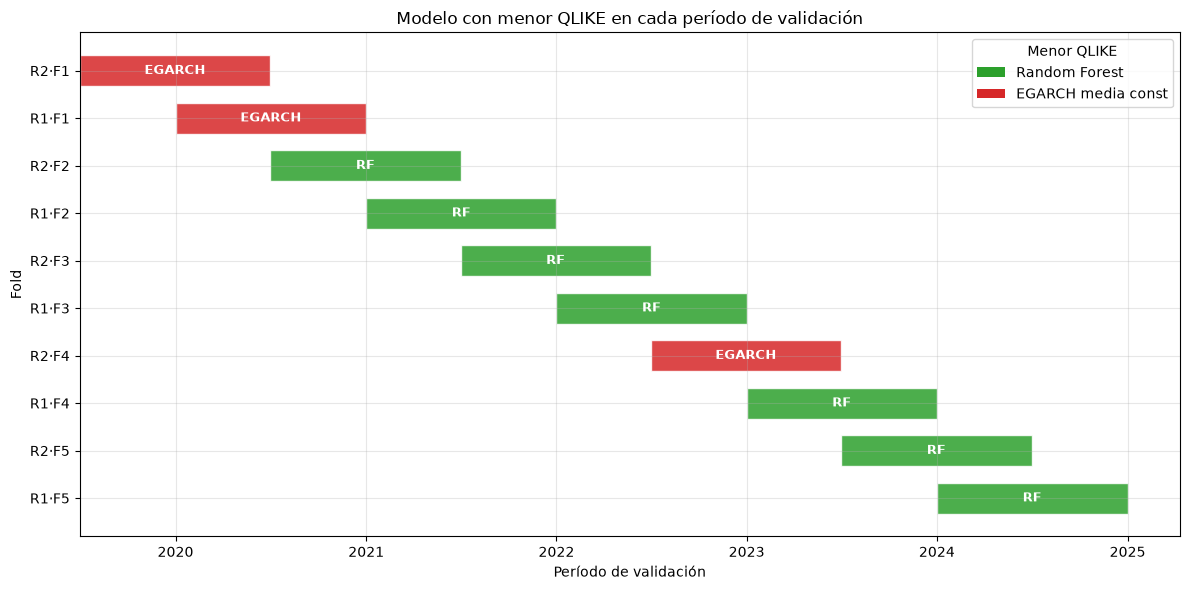

In [ ]:
periodos = tabla_folds.copy()
periodos["val_ini"] = pd.to_datetime(periodos["val_ini"])
periodos["val_fin"] = pd.to_datetime(periodos["val_fin"])
periodos = periodos.sort_values(
    ["val_ini", "rep", "fold"]
).reset_index(drop=True)

colores = {
    "Random Forest": "tab:green",
    "EGARCH": "tab:red",
}

fig, ax = plt.subplots(figsize=(12, 6))

for posicion, fila in periodos.iterrows():
    inicio = mdates.date2num(fila["val_ini"])
    fin = mdates.date2num(fila["val_fin"] + pd.Timedelta(days=1))
    modelo = fila["mejor_qlike"]
    nombre_corto = "RF" if modelo == "Random Forest" else "EGARCH"

    ax.barh(
        posicion,
        fin - inicio,
        left=inicio,
        height=0.65,
        color=colores[modelo],
        alpha=0.85,
        edgecolor="white",
    )
    ax.text(
        inicio + (fin - inicio) / 2,
        posicion,
        nombre_corto,
        ha="center",
        va="center",
        color="white",
        fontsize=9,
        fontweight="bold",
    )

ax.set_yticks(range(len(periodos)))
ax.set_yticklabels(periodos["etiqueta"])
ax.invert_yaxis()
ax.xaxis_date()
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

ax.set_xlabel("Período de validación")
ax.set_ylabel("Fold")
ax.set_title("Modelo con menor QLIKE en cada período de validación")
ax.legend(
    handles=[
        Patch(facecolor=colores["Random Forest"], label="Random Forest"),
        Patch(facecolor=colores["EGARCH"], label="EGARCH media const"),
    ],
    title="Menor QLIKE",
)
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig(FIG_DIR / "07_linea_tiempo_mejor_modelo.png", dpi=150)
plt.show()

Random Forest tiene un QLIKE promedio ligeramente menor que EGARCH con media constante (2.8487 frente a 2.8657) y obtiene el menor QLIKE en 7 de los 10 folds. Su ventaja aparece en la mayoría de los períodos evaluados, aunque EGARCH con media constante supera al Random Forest en tres folds, incluidos dos que abarcan 2020. La diferencia promedio de QLIKE es pequeña y Random Forest presenta mayor variabilidad entre folds.

En cambio, EGARCH con media constante obtiene menores valores de MSE, tanto en promedio como en mediana. Esta diferencia se relaciona especialmente con los errores extremos de algunos períodos, que pesan mucho en el MSE. Por tanto, el modelo preferido depende de la métrica: según QLIKE, Random Forest muestra una ventaja leve; según MSE, EGARCH con media constante.

La línea de tiempo muestra que la ventaja del Random Forest se concentra en la mayoría de los períodos desde 2021 hasta 2024. EGARCH con media constante obtiene mejor resultado en los folds que incluyen principalmente 2020 y en el período julio de 2022–junio de 2023.

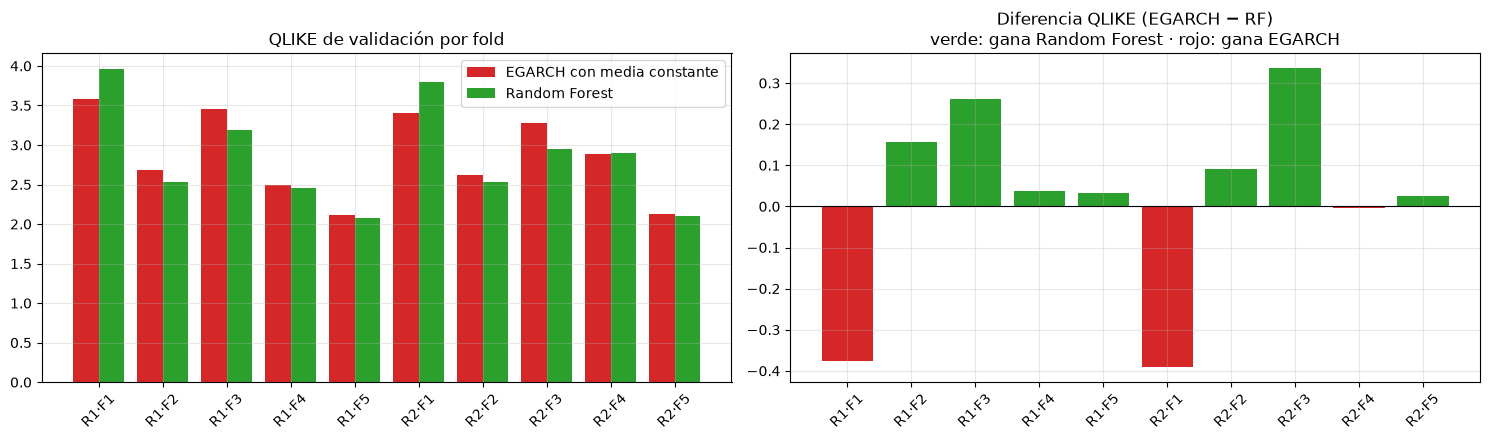

In [12]:
x = np.arange(len(tabla_folds))
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))

ax[0].bar(x - 0.2, tabla_folds["qlike_egarch"], 0.4, label="EGARCH con media constante", color="tab:red")
ax[0].bar(x + 0.2, tabla_folds["qlike_rf"], 0.4, label="Random Forest", color="tab:green")
ax[0].set_xticks(x, tabla_folds["etiqueta"], rotation=45)
ax[0].set_title("QLIKE de validación por fold"); ax[0].legend()

colores = np.where(tabla_folds["dif_qlike"] > 0, "tab:green", "tab:red")
ax[1].bar(x, tabla_folds["dif_qlike"], color=colores)
ax[1].axhline(0, color="black", lw=0.8)
ax[1].set_xticks(x, tabla_folds["etiqueta"], rotation=45)
ax[1].set_title("Diferencia QLIKE (EGARCH − RF)\nverde: gana Random Forest · rojo: gana EGARCH")

plt.tight_layout(); plt.savefig(FIG_DIR / "07_qlike_por_fold.png", dpi=150); plt.show()

El gráfico compara el QLIKE de validación de ambos modelos en cada fold. En **7 de los 10 folds**, Random Forest tiene menor QLIKE; en los otros tres, gana EGARCH con media constante. La diferencia más marcada a favor de Random Forest se observa en **R2·F3**, mientras que EGARCH con media constante presenta su mayor ventaja en **R2·F1**. En **R2·F4**, la diferencia es casi nula.

En conjunto, los resultados favorecen ligeramente a Random Forest según QLIKE, pero la ventaja cambia según el período y es pequeña en algunos folds. El gráfico muestra dónde gana cada modelo, pero no permite determinar si la diferencia general es estadísticamente significativa.

## 5. Pruebas de hipótesis sobre los 10 folds

Se comparan las pérdidas de validación de ambos modelos en los mismos 10 folds de Time Series Cross-Validation (2 repeticiones × 5 folds).

- $H_0$: ambos modelos tienen la misma pérdida de validación (la mediana de las diferencias es 0).
- $H_1$: las pérdidas son distintas.

**Wilcoxon de rangos con signo** es la prueba principal: no supone normalidad, adecuado con solo 10 pares. La **t pareada** se reporta como complemento, junto con la prueba de Shapiro-Wilk sobre las diferencias para revisar su supuesto de normalidad. [3], [4], [9]

Limitación: los folds de las dos repeticiones se superponen en el tiempo (comparten medio año de validación) y sus entrenamientos son anidados, por lo que los 10 pares no son completamente independientes. Por eso los resultados se complementan con la prueba de Diebold-Mariano.

In [13]:
pruebas_folds = pd.DataFrame([
    c.pruebas_pareadas(tabla_folds["qlike_egarch"], tabla_folds["qlike_rf"], "QLIKE"),
    c.pruebas_pareadas(tabla_folds["mse_egarch"], tabla_folds["mse_rf"], "MSE"),
]).set_index("métrica")
pruebas_folds["¿diferencia significativa (Wilcoxon, 5%)?"] = pruebas_folds["Wilcoxon p"] < ALFA
display(pruebas_folds.round(4))

# Normalidad de las diferencias (supuesto de la t pareada)
sw = stats.shapiro(tabla_folds["dif_qlike"])
print(f"Shapiro-Wilk de las diferencias de QLIKE: W = {sw.statistic:.3f}, p = {sw.pvalue:.4f}")

,media EGARCH,media RF,diferencia media (EGARCH − RF),folds con RF mejor,Wilcoxon W,Wilcoxon p,t pareada,t p,"¿diferencia significativa (Wilcoxon, 5%)?"
métrica,,,,,,,,,
QLIKE,2.8657,2.8487,0.0170,7,20.0,0.4922,0.2258,0.8264,False
MSE,989.1622,1324.4140,-335.2518,4,10.0,0.0840,-1.6348,0.1365,False


Shapiro-Wilk de las diferencias de QLIKE: W = 0.881, p = 0.1345


La prueba pareada **no detecta diferencias estadísticamente significativas (pvalor $\geq$ 0.05 , no se rechaza $H_{0}$)** entre EGARCH con media constante y Random Forest al nivel del 5 %, ni con QLIKE ni con MSE. 

Para QLIKE, Random Forest tuvo menor pérdida en 7 de los 10 folds y una media ligeramente inferior (2.8487 frente a 2.8657), pero la diferencia no fue significativa según Wilcoxon (*p* = 0.4922; *p* de la *t* pareada = 0.8264). 

Para MSE, la media favorece a EGARCH con media constante (989.16 frente a 1324.41), aunque tampoco se alcanzó significancia estadística (Wilcoxon *p* = 0.0840; *t* pareada *p* = 0.1365).

Por tanto, estos resultados no aportan evidencia suficiente para afirmar que uno de los modelos sea superior al otro en los folds evaluados. El test de Shapiro-Wilk para las diferencias de QLIKE (*p* = 0.1345) no detecta una desviación significativa de la normalidad, aunque esto no demuestra que las diferencias sean normales. Además, como algunos folds se solapan en el tiempo, los resultados de la prueba pareada deben interpretarse con cautela.

En conclusión, no se rechaza la hipótesis nula de que no hay diferencia en las pérdidas de los modelos y esto significa que los datos no dan evidencia suficiente para afirmar que las pérdidas sean distintas y tampoco demuestra que sean exactamente iguales.

## 6. Prueba de Diebold-Mariano

Compara la precisión de los pronósticos **día a día**. Para cada día objetivo se calcula $d_\tau = L_{\text{EGARCH},\tau} - L_{\text{RF},\tau}$, y se contrasta $H_0: E[d_\tau] = 0$ (igual precisión). Como las diferencias de pérdida diarias están autocorrelacionadas (la volatilidad es persistente), la varianza de la media se estima con el método de Newey-West (HAC). [5], [6]

Se aplica por separado a cada repetición para no contar dos veces los días que se repiten entre repeticiones. La repetición 1 cubre 2020–2024 sin solapamientos.

In [14]:
L_eg = c.perdidas(pron["y"], pron["h_egarch"]).set_index(pron.index)
L_rf = c.perdidas(pron["y"], pron["h_rf"]).set_index(pron.index)

filas_dm = []
for nombre, filtro in [("Repetición 1 (2020–2024, sin días repetidos)", pron["rep"] == 1),
                       ("Repetición 2 (jul 2019 – jun 2024)", pron["rep"] == 2)]:
    for met in ["qlike", "mse"]:
        r_dm = c.diebold_mariano(L_eg.loc[filtro.values, met], L_rf.loc[filtro.values, met])
        filas_dm.append({"muestra": nombre, "métrica": met.upper(), **r_dm})

dm_val = pd.DataFrame(filas_dm)
dm_val["¿significativo (5%)?"] = dm_val["p-valor"] < ALFA
dm_val["modelo con menor pérdida"] = np.where(dm_val["diferencia media"] > 0, "Random Forest", "EGARCH con media constante")
display(dm_val.round(4))

,muestra,métrica,T,rezagos HAC,diferencia media,DM,p-valor,¿significativo (5%)?,modelo con menor pérdida
0,"Repetición 1 (2020–2024, sin días repetidos)",QLIKE,1256,7,0.0224,0.3535,0.7238,False,Random Forest
1,"Repetición 1 (2020–2024, sin días repetidos)",MSE,1256,7,-334.8987,-1.6847,0.0923,False,EGARCH con media constante
2,Repetición 2 (jul 2019 – jun 2024),QLIKE,1256,7,0.0119,0.1848,0.8534,False,Random Forest
3,Repetición 2 (jul 2019 – jun 2024),MSE,1256,7,-335.2000,-1.7047,0.0885,False,EGARCH con media constante


En la prueba de Diebold–Mariano, ninguno de los resultados es estadísticamente significativo al 5 %: todos los p-valores son mayores que 0.05.

En ambas repeticiones, la diferencia media de QLIKE (EGARCH − Random Forest) es positiva, así que el promedio favorece ligeramente a Random Forest. Para MSE, la diferencia es negativa y favorece a EGARCH con media constante. Sin embargo, como los resultados no son significativos (p entre 0.0885 y 0.8534), no hay evidencia suficiente para concluir que un modelo tenga mayor precisión predictiva que el otro en estas muestras.

## 7. Referencia: pronóstico ingenuo
Para saber si los errores de ambos modelos son "buenos", se comparan con un pronóstico simple: la varianza de mañana es el promedio de Parkinson de los últimos 21 días (`park_media_21`). Si un modelo no supera esta referencia, no aporta información adicional a la que ya contiene la persistencia reciente de la volatilidad. [1]

In [15]:
X_full = pd.read_csv(PROC / "fe_features_X.csv", index_col=0, parse_dates=True)
pron["h_ingenuo"] = X_full["park_media_21"].reindex(pron.index).values

filas = []
for (rep, fold), g in pron.groupby(["rep", "fold"]):
    fila = {"rep": rep, "fold": fold}
    for col, nom in [("h_egarch", "egarch"), ("h_rf", "rf"), ("h_ingenuo", "ingenuo")]:
        L = c.perdidas(g["y"], g[col])
        fila[f"qlike_{nom}"] = L["qlike"].mean()
        fila[f"mse_{nom}"] = L["mse"].mean()
    filas.append(fila)
con_ingenuo = pd.DataFrame(filas)
display(con_ingenuo[["qlike_egarch", "qlike_rf", "qlike_ingenuo"]].agg(["mean", "std"]).round(4).T)

,mean,std
qlike_egarch,2.8657,0.5468
qlike_rf,2.8487,0.6490
qlike_ingenuo,2.8290,0.5579


In [16]:
L_eg = c.perdidas(pron["y"], pron["h_egarch"]).set_index(pron.index)
L_rf = c.perdidas(pron["y"], pron["h_rf"]).set_index(pron.index)
L_ing = c.perdidas(pron["y"], pron["h_ingenuo"]).set_index(pron.index)

comparaciones = [
    ("EGARCH con media constante", L_eg, "Random Forest", L_rf),
    ("EGARCH con media constante", L_eg, "Ingenuo", L_ing),
    ("Random Forest", L_rf, "Ingenuo", L_ing),
]

muestras = [
    ("Repetición 1 (2020–2024, sin días repetidos)", pron["rep"] == 1),
    ("Repetición 2 (jul 2019 – jun 2024)", pron["rep"] == 2),
]

filas_dm = []

for nombre_muestra, filtro in muestras:
    for met in ["qlike", "mse"]:
        for nombre_a, perdida_a, nombre_b, perdida_b in comparaciones:
            r_dm = c.diebold_mariano(
                perdida_a.loc[filtro.values, met],
                perdida_b.loc[filtro.values, met],
            )

            diferencia = r_dm["diferencia media"]
            if diferencia > 0:
                mejor = nombre_b
            elif diferencia < 0:
                mejor = nombre_a
            else:
                mejor = "Empate"

            filas_dm.append({
                "muestra": nombre_muestra,
                "métrica": met.upper(),
                "comparación": f"{nombre_a} − {nombre_b}",
                **r_dm,
                "modelo con menor pérdida": mejor,
            })

dm_val = pd.DataFrame(filas_dm)
dm_val["¿significativo (5%)?"] = dm_val["p-valor"] < ALFA

display(
    dm_val[
        [
            "muestra",
            "métrica",
            "comparación",
            "T",
            "diferencia media",
            "DM",
            "p-valor",
            "¿significativo (5%)?",
            "modelo con menor pérdida",
        ]
    ].round(4)
)

,muestra,métrica,comparación,T,diferencia media,DM,p-valor,¿significativo (5%)?,modelo con menor pérdida
0,"Repetición 1 (2020–2024, sin días repetidos)",QLIKE,EGARCH con media constante − Random Forest,1256,0.0224,0.3535,0.7238,False,Random Forest
1,"Repetición 1 (2020–2024, sin días repetidos)",QLIKE,EGARCH con media constante − Ingenuo,1256,0.0391,1.0362,0.3003,False,Ingenuo
2,"Repetición 1 (2020–2024, sin días repetidos)",QLIKE,Random Forest − Ingenuo,1256,0.0167,0.3118,0.7552,False,Ingenuo
3,"Repetición 1 (2020–2024, sin días repetidos)",MSE,EGARCH con media constante − Random Forest,1256,-334.8987,-1.6847,0.0923,False,EGARCH con media constante
4,"Repetición 1 (2020–2024, sin días repetidos)",MSE,EGARCH con media constante − Ingenuo,1256,-141.9415,-1.1204,0.2628,False,EGARCH con media constante
5,"Repetición 1 (2020–2024, sin días repetidos)",MSE,Random Forest − Ingenuo,1256,192.9573,0.7306,0.4652,False,Ingenuo
6,Repetición 2 (jul 2019 – jun 2024),QLIKE,EGARCH con media constante − Random Forest,1256,0.0119,0.1848,0.8534,False,Random Forest
7,Repetición 2 (jul 2019 – jun 2024),QLIKE,EGARCH con media constante − Ingenuo,1256,0.0346,0.9010,0.3678,False,Ingenuo
8,Repetición 2 (jul 2019 – jun 2024),QLIKE,Random Forest − Ingenuo,1256,0.0227,0.4203,0.6744,False,Ingenuo
9,Repetición 2 (jul 2019 – jun 2024),MSE,EGARCH con media constante − Random Forest,1256,-335.2000,-1.7047,0.0885,False,EGARCH con media constante


Aunque las pérdidas medias sugieren algunas diferencias entre modelos, la prueba de Diebold–Mariano no encuentra diferencias significativas en precisión predictiva al nivel del 5 % entre ningún par de modelos, en ninguna repetición ni con QLIKE ni con MSE: todos los p-valores son mayores que 0.05. Por tanto, no se rechaza la hipótesis nula de igual precisión predictiva.

En validación, el pronóstico ingenuo obtuvo la QLIKE media más baja de los tres (2,829), frente a 2,849 del Random Forest y 2,866 del EGARCH. Las diferencias son pequeñas comparadas con la variabilidad entre folds (desv. ≈ 0,55–0,65). Esto indica que gran parte de lo que se puede pronosticar de la volatilidad diaria proviene de su persistencia, que un promedio móvil simple ya captura.

## 8. Evaluación en el test final (2025 – oct 2026)

Ambos modelos ya están definidos: el EGARCH por el diagnóstico (notebook 03) y el Random Forest por Optuna (notebook 06). Se estiman **una sola vez con todo el periodo de desarrollo (2010–2024)** y se evalúan en el test, que no se usó en ninguna decisión previa. [7], [8], [10]
- **EGARCH con media constante:** parámetros estimados con el desarrollo; pronóstico a un paso para cada día del test con parámetros fijos.
- **Random Forest:** `pipeline.fit(X_desarrollo, y_desarrollo)` y `pipeline.predict(X_test)`.

Para ello primero ajustamos la data de train y test para la validación en cada modelo, cada uno usa sus propios datos de entrada: el EGARCH usa la serie de retornos y el Random Forest la tabla de variables construidas por rezagos

Las features del test se cargan de `fe_features_X_test.csv`, construidas con la misma extracción (20 rezagos y ventanas de 5, 21 y 63 días), usando la información de diciembre de 2024 para los rezagos de los primeros días de 2025. Esto ya fue construido en el notebook de `04.feature_extraction.ipynb`.

In [17]:
TEST_INI, TEST_FIN = pd.Timestamp(cfg.TEST_INI), pd.Timestamp(cfg.TEST_FIN)
DEV_FIN = pd.Timestamp(cfg.DEV_FIN)

# Cargar datos base; se necesitan para EGARCH y para las etiquetas
ret_dev = pd.read_csv(
    PROC / "train_validation.csv", index_col=0, parse_dates=True
)
ret_test = pd.read_csv(
    PROC / "test.csv", index_col=0, parse_dates=True
)

base_ret = pd.concat([ret_dev, ret_test]).sort_index()
base_ret = base_ret[~base_ret.index.duplicated(keep="first")]
r_full = base_ret["WTI"]

# Cargar features ya extraídas
X_dev = pd.read_csv(
    PROC / "fe_features_X.csv", index_col=0, parse_dates=True
)
X_test = pd.read_csv(
    PROC / "fe_features_X_test.csv", index_col=0, parse_dates=True
)

# Confirmar que desarrollo y test tienen las mismas variables y en el mismo orden
assert X_dev.columns.equals(X_test.columns), \
    "Las columnas de features de desarrollo y test no coinciden."

# Cargar las etiquetas Parkinson y alinearlas con las fechas de X
y_dev = ret_dev["WTI_park"].reindex(X_dev.index).rename("y")
y_test = ret_test["WTI_park"].reindex(X_test.index).rename("y")

# Comprobar alineación y ausencia de fechas duplicadas
assert X_dev.index.equals(y_dev.index)
assert X_test.index.equals(y_test.index)
assert X_dev.index.is_unique and X_test.index.is_unique
assert not X_dev.isna().any().any() and not X_test.isna().any().any()
assert not y_dev.isna().any() and not y_test.isna().any()

print(f"Desarrollo: {X_dev.shape} | Test: {X_test.shape}")
print(f"Fechas de test: {X_test.index.min().date()} → {X_test.index.max().date()}")

Desarrollo: (3706, 67) | Test: (461, 67)
Fechas de test: 2025-01-02 → 2026-10-30


In [18]:
park_full = base_ret["WTI_park"]
park_full

Date
2010-01-05    0.599044
2010-01-06    3.807394
2010-01-07    0.636423
2010-01-08    1.473154
2010-01-11    2.075756
                ...   
2026-10-26    2.732662
2026-10-27    4.029657
2026-10-28    5.041605
2026-10-29    3.615462
2026-10-30    2.197842
Name: WTI_park, Length: 4230, dtype: float64

### 8.1. Ajustar los modelos con todo el desarrollo y pronosticar el test

In [19]:
print(f"La data de train termina en: {DEV_FIN}, mientras que la de test comienza en {TEST_INI} y termina en {TEST_FIN}")


La data de train termina en: 2024-12-31 00:00:00, mientras que la de test comienza en 2025-01-01 00:00:00 y termina en 2026-10-31 00:00:00


#### Modelo con media constante y EGARCH(1,1,1)

Se especifica el modelo de media constante–EGARCH(1,1,1) con errores t, el mismo elegido en el notebook 03. En la notación de arch, p=1 es el rezago de la magnitud del choque ($\alpha$), o=1 el término asimétrico ($\gamma$), que permite que los choques positivos y negativos afecten de forma distinta la volatilidad, y q=1 el rezago del logaritmo de la varianza condicional ($\beta$). [7]

In [20]:
# EGARCH con media constante: ajustar con desarrollo y pronosticar el test a un paso

ESPEC3 = {
    "mean": "Constant",
    "vol": "EGARCH",
    "p": 1,
    "o": 1,
    "q": 1,
    "dist": "t",
}

Ahora, se llama a la función que estima el modelo y genera pronósticos. 
Devuelve:
- h_eg_test: varianzas pronosticadas para las fechas del test.
- res_eg_dev: resultados del modelo estimado con el período de desarrollo.

In [21]:

h_eg_test, res_eg_dev = ag.pronostico_egarch(
    r_full,
    DEV_FIN,
    TEST_INI,
    TEST_FIN,
    espec=ESPEC3,
)

In [22]:
h_eg_test

Date
2025-01-02    2.177758
2025-01-03    2.151287
2025-01-06    2.047038
2025-01-07    2.019549
2025-01-08    1.908750
                ...   
2026-10-26    6.336797
2026-10-27    6.412286
2026-10-28    6.692856
2026-10-29    6.402961
2026-10-30    6.089940
Name: h_egarch, Length: 461, dtype: float64

A continuación se presenta el modelo estimado con todo el periodo de desarrollo (2010–2024). Frente al tramo de diagnóstico (2010 – junio 2019), la persistencia baja ligeramente ($\beta = 0{,}984$ frente a $0{,}992$), el efecto de la magnitud de los choques aumenta ($\alpha = 0{,}143$ frente a $0{,}081$) y los grados de libertad bajan ($\nu = 7{,}14$ frente a $8{,}61$), lo que indica colas más pesadas. Estos cambios reflejan los choques más intensos del periodo 2020–2024. [7]

In [23]:
res_eg_dev

                        Constant Mean - EGARCH Model Results                        
Dep. Variable:                          WTI   R-squared:                       0.000
Mean Model:                   Constant Mean   Adj. R-squared:                  0.000
Vol Model:                           EGARCH   Log-Likelihood:               -7938.87
Distribution:      Standardized Student's t   AIC:                           15889.7
Method:                  Maximum Likelihood   BIC:                           15927.1
                                              No. Observations:                 3769
Date:                      Fri, Nov 20 2026   Df Residuals:                     3768
Time:                              14:16:12   Df Model:                            1
                                  Mean Model                                 
                 coef    std err          t      P>|t|       95.0% Conf. Int.
-----------------------------------------------------------------------------
m

In [24]:
display(res_eg_dev.params.round(4).to_frame("Parámetros EGARCH"))

,Parámetros EGARCH
mu,0.0281
omega,0.0250
alpha[1],0.1430
gamma[1],-0.0745
beta[1],0.9844
nu,7.1408


Se eleva al cuadrado porque `res_eg_dev.conditional_volatility` no contiene los retornos observados: contiene la desviación estándar condicional estimada por EGARCH, $\hat{\sigma}_t$. Al cuadrarla, se obtiene la varianza estimada, $\hat{\sigma}_t^2$. [1], [7]

Esto permite comparar magnitudes equivalentes: el objetivo WTI_park es un proxy de varianza expresado en %², y `h_eg_test` también contiene pronósticos de varianza. Por tanto, `h_eg_dev` debe estar en esa misma escala para calcular QLIKE y MSE de forma consistente entre los dos modelos.

In [25]:
# Varianza estimada dentro del desarrollo, para el resumen posterior
h_eg_dev = pd.Series(
    np.asarray(res_eg_dev.conditional_volatility) ** 2,
    index=r_full.loc[:DEV_FIN].index,
)

In [26]:
h_eg_dev

Date
2010-01-05    2.651548
2010-01-06    2.418312
2010-01-07    2.349554
2010-01-08    2.327548
2010-01-11    2.108953
                ...   
2024-12-24    2.791515
2024-12-26    2.640355
2024-12-27    2.618083
2024-12-30    2.500005
2024-12-31    2.306105
Length: 3769, dtype: float64

#### Modelo Random Forest con rezagos

Para la evaluación final, se construye un pipeline de Random Forest con los mejores hiperparámetros encontrados por Optuna durante la validación cruzada. Al ajustarlo con todo el período de desarrollo (`X_dev`, `y_dev`), el pipeline selecciona las 16 variables con mayor información mutua respecto al objetivo y entrena el modelo únicamente con ellas. [8], [10] 


In [27]:
PARAMS_RF

{'n_estimators': 350,
 'max_depth': 7,
 'min_samples_leaf': 10,
 'max_features': 0.9603717170427477}

In [28]:
# Random Forest: el pipeline selecciona variables y se ajusta solo con desarrollo
pipe_final = rf.crear_pipeline(K_FINAL, **PARAMS_RF)
pipe_final.fit(X_dev, y_dev)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('seleccion', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](67,)","['r2_lag1','absr_lag1','park_lag1',...,'vol_r_63','park_media_63','r_lag1']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,67
,"score_func score_func: callable, default=f_classifFunction taking two arrays X and y, and returning a pair of arrays(scores, pvalues) or a single array with scores.Default is f_classif (see below ""See Also""). The default function onlyworks with classification tasks... versionadded:: 0.18",functools.par...ndom_state=42)
,"k k: int or ""all"", default=10Number of top features to select.The ""all"" option bypasses selection, for use in a parameter search.",16
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](67,)","['r2_lag1','absr_lag1','park_lag1',...,'vol_r_63','park_media_63','r_lag1']"


Las variables que seleccionó el pipeline son las siguientes: 

In [29]:
vars_final = X_dev.columns[
    pipe_final.named_steps["seleccion"].get_support()
].tolist()

print("Variables seleccionadas:", vars_final)

Variables seleccionadas: ['park_lag1', 'park_lag2', 'park_lag3', 'park_lag4', 'park_lag5', 'park_lag6', 'park_lag7', 'park_lag8', 'park_lag9', 'park_lag18', 'vol_r_5', 'park_media_5', 'vol_r_21', 'park_media_21', 'vol_r_63', 'park_media_63']


A continuación, se generan los pronósticos del Random Forest para dos periodos: el desarrollo y el test.

- h_rf_dev genera predicciones para las fechas de X_dev, hasta el 31 de diciembre de 2024. Como el modelo se entrenó con esos mismos datos, son predicciones dentro de muestra; sirven para calcular el error de entrenamiento, pero no representan una evaluación independiente.
- h_rf_test genera predicciones para las fechas de X_test, del 2 de enero de 2025 al 30 de octubre de 2026. Esas son las predicciones para la evaluación final.

`clip` limita los pronósticos del test para que no sean menores que `H_MIN`. Si después calculas las pérdidas con c.perdidas, esa función también aplica un mínimo internamente.

In [30]:
h_rf_dev = pd.Series(
    pipe_final.predict(X_dev),
    index=X_dev.index,
)


In [31]:
h_rf_test = pd.Series(
    np.clip(pipe_final.predict(X_test), H_MIN, None),
    index=X_test.index,
)


In [32]:
h_rf_dev

Date
2010-04-07    1.838405
2010-04-08    1.817659
2010-04-09    1.849892
2010-04-12    1.824813
2010-04-13    1.873402
                ...   
2024-12-24    1.953482
2024-12-26    1.900380
2024-12-27    1.819984
2024-12-30    1.811207
2024-12-31    1.817675
Length: 3706, dtype: float64

In [33]:
h_rf_test

Date
2025-01-02    1.814431
2025-01-03    1.815240
2025-01-06    1.814301
2025-01-07    1.808014
2025-01-08    1.834775
                ...   
2026-10-26    8.918818
2026-10-27    7.905158
2026-10-28    4.799966
2026-10-29    4.581883
2026-10-30    4.541146
Length: 461, dtype: float64

En este paso se reúnen, por fecha, el Parkinson observado del test (`y`), los pronósticos a un paso de EGARCH con media constante y Random Forest, y un pronóstico ingenuo basado en `park_media_21`, que usa el promedio de Parkinson de las 21 sesiones anteriores. Este último sirve como referencia sencilla para comprobar si los modelos ofrecen una mejora frente a una estimación basada en la volatilidad reciente. 

`dropna()` conserva únicamente las fechas con dato observado y pronóstico disponible para los tres métodos. El período evaluado abarca las sesiones de mercado desde enero de 2025 hasta octubre de 2026: son **461 días**.

In [34]:
test = pd.DataFrame({"y": y_test, "h_egarch": h_eg_test, "h_rf": h_rf_test,
                     "h_ingenuo": X_test["park_media_21"]}).dropna()
print(f"Días del test evaluados por los tres: {len(test)} | {test.index.min().date()} → {test.index.max().date()}")



Días del test evaluados por los tres: 461 | 2025-01-02 → 2026-10-30


In [35]:
test

,y,h_egarch,h_rf,h_ingenuo
Date,,,,
2025-01-02,2.564396,2.177758,1.814431,1.779932
2025-01-03,1.816560,2.151287,1.815240,1.830110
2025-01-06,2.105162,2.047038,1.814301,1.722804
2025-01-07,1.334654,2.019549,1.808014,1.677942
2025-01-08,2.970515,1.908750,1.834775,1.690633
...,...,...,...,...
2026-10-26,2.732662,6.336797,8.918818,8.213012
2026-10-27,4.029657,6.412286,7.905158,8.135221
2026-10-28,5.041605,6.692856,4.799966,7.781663


Las pérdidas cuantifican la diferencia entre la varianza pronosticada $h$ y el estimador de Parkinson observado (`y_true`), utilizado como *proxy* de la varianza real, que no se observa directamente. [1], [2] 
El MSE calcula el error al cuadrado, $(y_{\text{true}}-h)^2$, por lo que penaliza con mayor intensidad los errores grandes. QLIKE, calculada como $y_{\text{true}}/h+\ln(h)$, es una función de pérdida adecuada para comparar pronósticos de volatilidad. 

Antes de calcularla, `np.clip` garantiza que los pronósticos sean positivos, condición necesaria para el logaritmo y la división. La función obtiene ambas pérdidas para cada día y, al promediarlas, permite comparar el desempeño de los modelos: valores menores indican menor pérdida. La fórmula de QLIKE omite términos que dependen únicamente de `y_true`; como los modelos se evalúan sobre los mismos días, esto no altera su comparación.

A continuación, para cada modelo se obtiene las pérdidas diarias de cada método en el período de test: EGARCH con media constante, Random Forest y el pronóstico ingenuo basado en la media móvil de Parkinson de 21 días. Para cada modelo obtiene el promedio de MSE y QLIKE, y presenta ambos valores redondeados a cuatro decimales para facilitar la comparación.

In [36]:
errores_test = pd.DataFrame({
    nom: c.perdidas(test["y"], test[col]).mean()
    for nom, col in [("EGARCH con media constante", "h_egarch"), ("Random Forest", "h_rf"), ("Ingenuo (media 21 días)", "h_ingenuo")]
}).T
display(errores_test.round(4))



,mse,qlike
EGARCH con media constante,815.3808,3.2388
Random Forest,729.3937,2.8390
Ingenuo (media 21 días),784.2076,2.9740


En esta salida, Random Forest tiene las menores pérdidas promedio: MSE de 729.3937 y QLIKE de 2.8390. Le sigue el pronóstico ingenuo, con MSE de 784.2076 y QLIKE de 2.9740; EGARCH con media constante presenta los valores más altos, con MSE de 815.3808 y QLIKE de 3.2388. 


Descriptivamente, Random Forest tuvo el mejor desempeño en este test según ambas métricas. Para afirmar que la diferencia es estadísticamente significativa, hay que revisar también la prueba Diebold–Mariano del test.

In [37]:
perdidas_test = {
    "EGARCH con media constante": c.perdidas(test["y"], test["h_egarch"]),
    "Random Forest": c.perdidas(test["y"], test["h_rf"]),
    "Ingenuo (media 21 días)": c.perdidas(test["y"], test["h_ingenuo"]),
}

comparaciones = [
    ("EGARCH con media constante", "Random Forest"),
    ("EGARCH con media constante", "Ingenuo (media 21 días)"),
    ("Random Forest", "Ingenuo (media 21 días)"),
]

filas_dm = []

for metrica in ["qlike", "mse"]:
    for modelo_a, modelo_b in comparaciones:
        resultado = c.diebold_mariano(
            perdidas_test[modelo_a][metrica],
            perdidas_test[modelo_b][metrica],
        )

        diferencia = resultado["diferencia media"]
        if diferencia > 0:
            menor_perdida = modelo_b
        elif diferencia < 0:
            menor_perdida = modelo_a
        else:
            menor_perdida = "Empate"

        filas_dm.append({
            "métrica": metrica.upper(),
            "comparación": f"{modelo_a} − {modelo_b}",
            **resultado,
            "¿significativo (5%)?": resultado["p-valor"] < ALFA,
            "modelo con menor pérdida": menor_perdida,
        })

dm_test = pd.DataFrame(filas_dm)

display(
    dm_test
    .set_index(["métrica", "comparación"])
    .round(4)
    .T
)

métrica                                                       QLIKE  \
comparación              EGARCH con media constante − Random Forest   
T                                                               461   
rezagos HAC                                                       5   
diferencia media                                             0.3998   
DM                                                           1.4543   
p-valor                                                      0.1465   
¿significativo (5%)?                                          False   
modelo con menor pérdida                              Random Forest   

métrica                                                                        \
comparación              EGARCH con media constante − Ingenuo (media 21 días)   
T                                                                       461     
rezagos HAC                                                               5     
diferencia media                                                     0.2648     
DM                                                                   1.4038     
p-valor                                                               0.161     
¿significativo (5%)?                                                  False     
modelo con menor pérdida                            Ingenuo (media 21 días)     

métrica                                                           \
comparación              Random Forest − Ingenuo (media 21 días)   
T                                                            461   
rezagos HAC                                                    5   
diferencia media                                          -0.135   
DM                                                        -1.412   
p-valor                                                   0.1586   
¿significativo (5%)?                                       False   
modelo con menor pérdida                           Random Forest   

métrica                                                         MSE  \
comparación              EGARCH con media constante − Random Forest   
T                                                               461   
rezagos HAC                                                       5   
diferencia media                                            85.9871   
DM                                                           0.3566   
p-valor                                                      0.7215   
¿significativo (5%)?                                          False   
modelo con menor pérdida                              Random Forest   

métrica                                                                        \
comparación              EGARCH con media constante − Ingenuo (media 21 días)   
T                                                                       461     
rezagos HAC                                                               5     
diferencia media                                                    31.1732     
DM                                                                   0.8617     
p-valor                                                              0.3893     
¿significativo (5%)?                                                  False     
modelo con menor pérdida                            Ingenuo (media 21 días)     

métrica                                                           
comparación              Random Forest − Ingenuo (media 21 días)  
T                                                            461  
rezagos HAC                                                    5  
diferencia media                                        -54.8138  
DM                                                       -0.2532  
p-valor                                                   0.8002  
¿significativo (5%)?                                       False  
modelo con menor pérdida                           Random Forest

Este bloque compara por pares los pronósticos de **EGARCH con media constante, Random Forest y el ingenuo basado en `park_media_21`** durante el test, mediante la prueba de Diebold–Mariano. La prueba se aplica por separado a QLIKE y MSE. En cada comparación, la diferencia se calcula como **modelo A − modelo B**: si es positiva, el modelo B tuvo menor pérdida media; si es negativa, la tuvo el modelo A. Un *p*-valor inferior a 0.05 indicaría una diferencia estadísticamente significativa. [5], [6]

En las **461 observaciones** del test, con 5 rezagos HAC, **ninguna comparación es significativa al 5 %**. Los *p*-valores para QLIKE son 0.1465 (EGARCH–Random Forest), 0.1610 (EGARCH–ingenuo) y 0.1586 (Random Forest–ingenuo); para MSE son 0.7215, 0.3893 y 0.8002, respectivamente. Aunque los promedios de pérdida favorecen descriptivamente a Random Forest en ambas métricas, no hay evidencia estadística suficiente para concluir que sea superior a los otros dos pronósticos en el test.



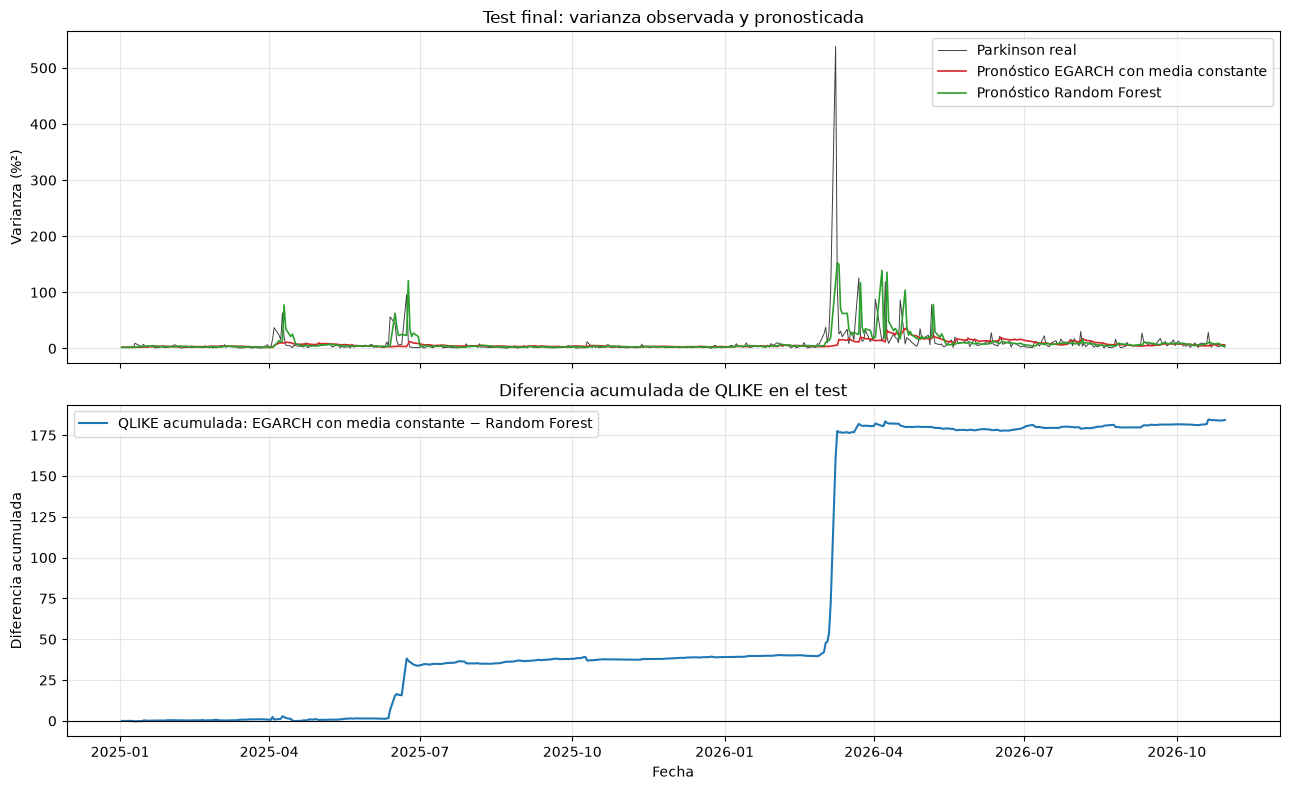

In [38]:
# Pérdidas diarias en el test
L_eg_t = c.perdidas(test["y"], test["h_egarch"])
L_rf_t = c.perdidas(test["y"], test["h_rf"])

# Diferencia diaria de QLIKE: positiva cuando favorece a Random Forest
d_test = L_eg_t["qlike"].to_numpy() - L_rf_t["qlike"].to_numpy()

fig, ax = plt.subplots(2, 1, figsize=(13, 8), sharex=True)

# Pronósticos frente al Parkinson observado
ax[0].plot(
    test.index, test["y"],
    lw=0.7, color="black", alpha=0.75, label="Parkinson real"
)
ax[0].plot(
    test.index, test["h_egarch"],
    lw=1.2, color="tab:red", label="Pronóstico EGARCH con media constante"
)
ax[0].plot(
    test.index, test["h_rf"],
    lw=1.2, color="tab:green", label="Pronóstico Random Forest"
)
ax[0].set_title("Test final: varianza observada y pronosticada")
ax[0].set_ylabel("Varianza (%²)")
ax[0].legend()

# Diferencia acumulada de QLIKE
ax[1].plot(
    test.index,
    np.cumsum(d_test),
    color="tab:blue",
    label="QLIKE acumulada: EGARCH con media constante − Random Forest"
)
ax[1].axhline(0, color="black", lw=0.8)
ax[1].set_title("Diferencia acumulada de QLIKE en el test")
ax[1].set_ylabel("Diferencia acumulada")
ax[1].set_xlabel("Fecha")
ax[1].legend()

plt.tight_layout()
plt.savefig(FIG_DIR / "07_test_final.png", dpi=150)
plt.show()

El panel superior compara el Parkinson observado con los pronósticos en el test. En los periodos tranquilos, ambos modelos pronostican valores bajos y parecidos. En los picos de abril y junio de 2025, y sobre todo en marzo de 2026 (Parkinson ≈ 540 %²), el Random Forest aumenta su pronóstico con más rapidez, mientras que el EGARCH reacciona poco y mantiene una varianza pronosticada baja.

El panel inferior muestra la diferencia acumulada de QLIKE (EGARCH − Random Forest); cuando sube, el Random Forest acumula ventaja. La curva es casi plana la mayor parte del test y sube en dos saltos: en junio de 2025 y en marzo de 2026. La ventaja del Random Forest en el test se debe principalmente a esos dos episodios, lo que explica por qué la prueba de Diebold-Mariano no la considera significativa: depende de pocos días.

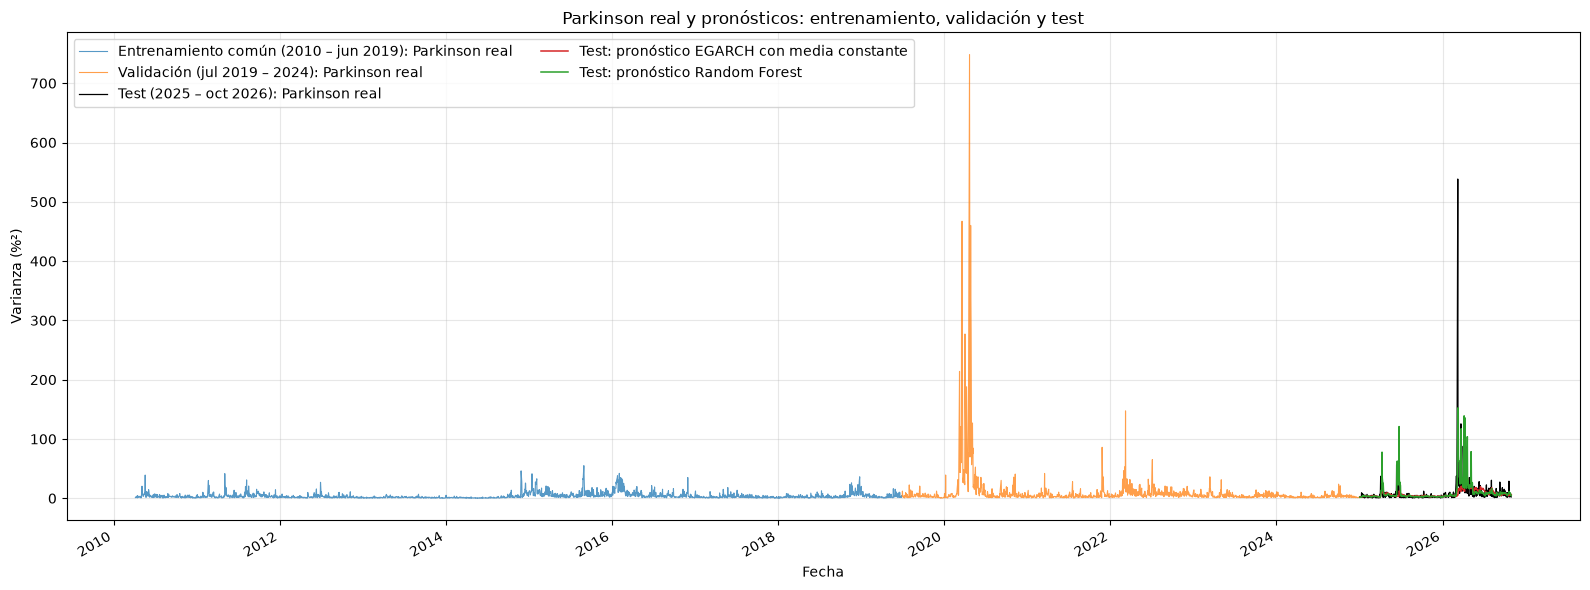

In [45]:
# Parkinson observado en el entrenamiento común (hasta jun 2019, el train más corto de los folds)
train_y = y_dev.loc[:FOLDS["train_fin"].min()].dropna().sort_index()

# Parkinson observado en validación: una observación por fecha
val_y = (
    pron[["y"]]
    .reset_index()
    .drop_duplicates(subset="Date")
    .set_index("Date")["y"]
    .sort_index()
)

fig, ax = plt.subplots(figsize=(16, 6))

ax.plot(
    train_y.index,
    train_y,
    color="tab:blue",
    linewidth=0.8,
    alpha=0.75,
    label="Entrenamiento común (2010 – jun 2019): Parkinson real",
)

ax.plot(
    val_y.index,
    val_y,
    color="tab:orange",
    linewidth=0.8,
    alpha=0.75,
    label="Validación (jul 2019 – 2024): Parkinson real",
)

ax.plot(
    test.index,
    test["y"],
    color="black",
    linewidth=0.9,
    label="Test (2025 – oct 2026): Parkinson real",
)

ax.plot(
    test.index,
    test["h_egarch"],
    color="tab:red",
    linewidth=1.1,
    label="Test: pronóstico EGARCH con media constante",
)

ax.plot(
    test.index,
    test["h_rf"],
    color="tab:green",
    linewidth=1.1,
    label="Test: pronóstico Random Forest",
)

ax.set_title("Parkinson real y pronósticos: entrenamiento, validación y test")
ax.set_xlabel("Fecha")
ax.set_ylabel("Varianza (%²)")
ax.legend(ncol=2)
ax.grid(True, alpha=0.3)
fig.autofmt_xdate()
plt.tight_layout()
plt.savefig(FIG_DIR / "07_parkinson_train_val_test.png", dpi=150)
plt.show()

La gráfica muestra que la volatilidad cambia mucho con el tiempo y que hay picos muy altos, especialmente en 2020 y 2026. Como la mayoría de los valores son mucho más bajos, en la gráfica parecen estar cerca de cero.

Durante el test, ambos modelos pronostican valores bajos en los períodos tranquilos. Cuando aparecen picos, Random Forest muestra algunos aumentos mayores, mientras que EGARCH con media constante produce pronósticos más suaves. La gráfica general no permite comparar bien esos momentos, así que conviene ampliarlos.

Esta gráfica ayuda a observar el comportamiento de los datos, pero no basta para decir qué modelo es mejor. Aunque Random Forest tuvo menores pérdidas promedio en el test, la prueba de Diebold–Mariano no encontró una diferencia estadísticamente significativa frente a EGARCH con media constante.

In [40]:
import plotly.graph_objects as go

test_plot = test.sort_index()

fig = go.Figure()

fig.add_trace(go.Scatter(
    x=test_plot.index,
    y=test_plot["y"],
    mode="lines",
    name="Parkinson real",
    line=dict(color="black", width=1.5),
))

fig.add_trace(go.Scatter(
    x=test_plot.index,
    y=test_plot["h_egarch"],
    mode="lines",
    name="Pronóstico EGARCH con media constante",
    line=dict(color="firebrick", width=1.5),
))

fig.add_trace(go.Scatter(
    x=test_plot.index,
    y=test_plot["h_rf"],
    mode="lines",
    name="Pronóstico Random Forest",
    line=dict(color="seagreen", width=1.5),
))

fig.update_layout(
    title="Test: Parkinson real y pronósticos de volatilidad",
    xaxis_title="Fecha",
    yaxis_title="Varianza (%²)",
    hovermode="x unified",
    template="plotly_white",
    legend=  dict(
        orientation="h",
        x=0,
        y=0.9,
        xanchor="left",
        yanchor="bottom",
    ),
    height=650,
    xaxis=dict(
        rangeselector=dict(
            buttons=[
                dict(count=1, label="1 mes", step="month", stepmode="backward"),
                dict(count=3, label="3 meses", step="month", stepmode="backward"),
                dict(count=6, label="6 meses", step="month", stepmode="backward"),
                dict(count=1, label="1 año", step="year", stepmode="backward"),
                dict(step="all", label="Todo"),
            ]
        ),
        rangeslider=dict(visible=True),
        type="date",
    ),
)

fig.show()

## 9. Ajuste: entrenamiento vs. validación vs. test
- **Train ≈ validación ≈ test:** buen ajuste y buena generalización.
- **Train mucho menor que validación:** posible sobreajuste, que debe confirmarse con el test.
- **Errores similares o peores que el pronóstico ingenuo:** el modelo no aporta información adicional a la persistencia reciente.
- **Validación ≈ test:** la validación cruzada fue un buen estimador del desempeño real.

El error de train corresponde a los modelos estimados con todo el desarrollo (los mismos que se evalúan en el test).

In [41]:
L_eg_t = perdidas_test["EGARCH con media constante"]
L_rf_t = perdidas_test["Random Forest"]

In [ ]:
d_eg = pd.concat({"y": y_dev, "h": h_eg_dev}, axis=1).dropna()
d_rf = pd.concat({"y": y_dev, "h": h_rf_dev}, axis=1).dropna()
d_in = pd.concat({"y": y_dev, "h": X_dev["park_media_21"]}, axis=1).dropna()

def fila_ajuste(nombre, L_train, val_qlike, val_mse, L_test):
    return {"modelo": nombre,
            "QLIKE train": L_train["qlike"].mean(),
            "QLIKE validación (media 10 folds)": val_qlike.mean(),
            "QLIKE validación (desv.)": val_qlike.std(),
            "QLIKE test": L_test["qlike"].mean(),
            "MSE train": L_train["mse"].mean(),
            "MSE validación (media)": val_mse.mean(),
            "MSE test": L_test["mse"].mean()}

ajuste = pd.DataFrame([
    fila_ajuste("EGARCH con media constante", c.perdidas(d_eg["y"], d_eg["h"]),
                tabla_folds["qlike_egarch"], tabla_folds["mse_egarch"], L_eg_t),
    fila_ajuste("Random Forest", c.perdidas(d_rf["y"], d_rf["h"]),
                tabla_folds["qlike_rf"], tabla_folds["mse_rf"], L_rf_t),
    fila_ajuste("Ingenuo (media 21 días)", c.perdidas(d_in["y"], d_in["h"]),
                con_ingenuo["qlike_ingenuo"], con_ingenuo["mse_ingenuo"],
                c.perdidas(test["y"], test["h_ingenuo"])),
]).set_index("modelo")
ajuste["brecha validación − train"] = ajuste["QLIKE validación (media 10 folds)"] - ajuste["QLIKE train"]
ajuste["brecha test − validación"] = ajuste["QLIKE test"] - ajuste["QLIKE validación (media 10 folds)"]
display(ajuste.round(4).T)

modelo,EGARCH con media constante,Random Forest,Ingenuo (media 21 días)
QLIKE train,2.3743,2.2969,2.3786
QLIKE validación (media 10 folds),2.8657,2.8487,2.8290
QLIKE validación (desv.),0.5468,0.6490,0.5579
QLIKE test,3.2388,2.8390,2.9740
MSE train,323.1513,249.3800,394.4263
MSE validación (media),989.1622,1324.4140,1128.8668
MSE test,815.3808,729.3937,784.2076
brecha validación − train,0.4914,0.5518,0.4504
brecha test − validación,0.3731,-0.0097,0.1451


La brecha entre *train* y validación puede señalar que el error dentro de muestra es optimista, pero **por sí sola no demuestra sobreajuste**. Para evaluarlo también hay que mirar el test, que representa datos no usados para ajustar el modelo. Se encontró lo siguiente:

- **Random Forest:** el QLIKE de entrenamiento (2.2969) es menor que el de validación (2.8487), con una brecha de 0.5518. Esto muestra un ajuste más favorable dentro de muestra. Sin embargo, su QLIKE de test (2.8390) es casi igual al de validación; por tanto, no se observa un deterioro al pasar al test. La validación fue un buen estimador de su QLIKE final.
- **EGARCH con media constante:** el QLIKE aumenta de 2.8657 en validación a 3.2388 en test. La validación subestimó la pérdida del período final. Esto sugiere que el desempeño fue menos estable fuera de la muestra de validación, aunque el cambio también puede deberse a diferencias entre períodos; no basta para atribuirlo a sobreajuste.
- **Pronóstico ingenuo:** no se entrena un modelo, así que no corresponde diagnosticar sobreajuste a partir de su brecha *train–validación*. Su QLIKE pasa de 2.8290 en validación a 2.9740 en test: la validación se acercó al resultado final, aunque lo estimó algo por debajo.

En conjunto, **la validación representó bien el QLIKE de test de Random Forest**, pero fue menos precisa para EGARCH con media constante. Para MSE, los promedios de validación son mayores que los de test en los tres casos, así que la validación no reprodujo la magnitud del error final con esa métrica. En el test, Random Forest obtiene el menor QLIKE y MSE, pero la prueba Diebold–Mariano no encontró diferencias significativas frente a EGARCH con media constante. Por eso, los resultados favorecen descriptivamente a Random Forest, sin demostrar que sea estadísticamente superior.

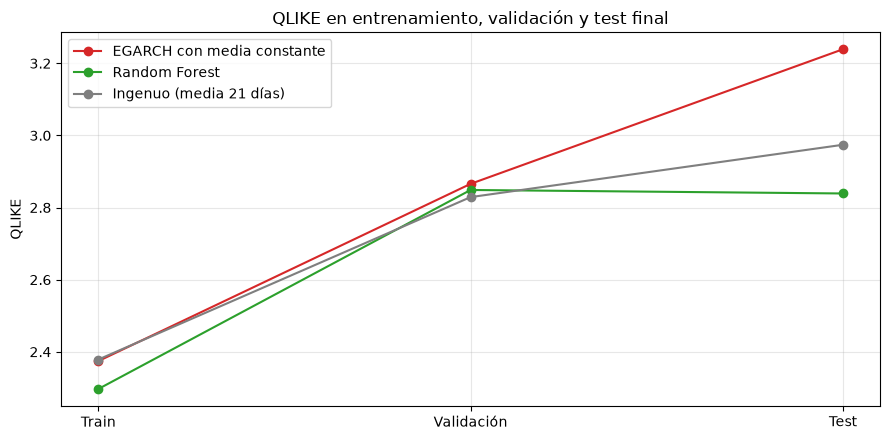

In [43]:
fig, ax = plt.subplots(figsize=(9, 4.5))
partes = ["QLIKE train", "QLIKE validación (media 10 folds)", "QLIKE test"]
for modelo, color in zip(ajuste.index, ["tab:red", "tab:green", "tab:grey"]):
    ax.plot(["Train", "Validación", "Test"], ajuste.loc[modelo, partes], "o-", color=color, label=modelo)
ax.set_ylabel("QLIKE"); ax.set_title("QLIKE en entrenamiento, validación y test final")
ax.legend(); plt.tight_layout(); plt.savefig(FIG_DIR / "07_train_val_test.png", dpi=150); plt.show()

La gráfica muestra que el QLIKE aumenta del entrenamiento a la validación para los tres métodos. En el test, **Random Forest mantiene un valor cercano al de validación** (≈2.84), mientras que EGARCH con media constante empeora (≈3.24) y el pronóstico ingenuo también sube moderadamente (≈2.97). Esto sugiere que la validación anticipó bien el desempeño de Random Forest en el test, pero fue más optimista para EGARCH con media constante. Aunque Random Forest obtiene el menor QLIKE en el test, la gráfica es descriptiva y no demuestra por sí sola que su ventaja sea estadísticamente significativa.

## 10. Guardar

In [44]:
tabla_folds.to_csv(CMP_DIR / "comparacion_por_fold.csv", index=False)
resumen_val.to_csv(CMP_DIR / "resumen_validacion.csv")
pruebas_folds.to_csv(CMP_DIR / "pruebas_wilcoxon_t.csv")
dm_val.to_csv(CMP_DIR / "diebold_mariano_validacion.csv", index=False)
con_ingenuo.to_csv(CMP_DIR / "comparacion_con_ingenuo.csv", index=False)
test.to_csv(CMP_DIR / "pronosticos_test.csv")
errores_test.to_csv(CMP_DIR / "errores_test.csv")
dm_test.to_csv(CMP_DIR / "diebold_mariano_test.csv", index=False)
ajuste.to_csv(CMP_DIR / "train_validacion_test.csv")
print("Resultados guardados en", CMP_DIR)

Resultados guardados en c:\Users\ASUS\Desktop\Maestria IA USFQ\AprendizajeSupervisado\Proyectofinal_ml_wti\results\comparacion


## 11. Conclusiones

1. **Validación (10 folds).** El Random Forest obtuvo una QLIKE media ligeramente menor que el EGARCH con media constante (2,8487 frente a 2,8657) y fue mejor en 7 de los 10 folds, principalmente en los periodos de 2021 a 2024. El EGARCH con media constante fue mejor en los dos folds que incluyen la crisis de 2020 y obtuvo un MSE medio menor (989,2 frente a 1.324,4), métrica dominada por los días extremos de ese año. [1], [2]

2. **Pruebas de hipótesis.** La prueba de Wilcoxon sobre los 10 folds no encontró diferencias significativas al 5 % ni en QLIKE (*p* = 0,492) ni en MSE (*p* = 0,084); la *t* pareada coincide (*p* = 0,826 y 0,137). La prueba de Diebold-Mariano sobre los pronósticos diarios confirma el resultado en ambas repeticiones (QLIKE: *p* = 0,724 y 0,853; MSE: *p* = 0,092 y 0,089). No hay evidencia estadística de que un modelo pronostique la volatilidad mejor que el otro. [3], [4], [5], [6]

3. **Dependencia del régimen.** La ventaja de cada modelo depende del periodo. En periodos de volatilidad moderada, el Random Forest aprovecha bien los rezagos y promedios del estimador de Parkinson. En episodios extremos como marzo–abril de 2020 subestima los picos, porque un Random Forest no puede pronosticar valores fuera del rango observado en el entrenamiento; el EGARCH con media constante, en cambio, responde a los choques grandes a través de su ecuación de varianza. [7], [8] En el test, sin embargo, ocurrió lo contrario: durante el pico de marzo de 2026 el Random Forest elevó su pronóstico mucho más rápido que el EGARCH, cuya varianza pronosticada se mantuvo baja. La ventaja del Random Forest en el test se concentra en dos episodios (junio de 2025 y marzo de 2026); fuera de ellos, ambos modelos tienen pérdidas similares. Por eso, qué modelo responde mejor a los extremos depende del episodio, y la ventaja del test no es significativa.

4. **Referencia ingenua.** Un pronóstico simple basado en el promedio de Parkinson de los últimos 21 días obtuvo una QLIKE de validación de 2,8290, menor que la de ambos modelos, aunque sin diferencias significativas (Diebold-Mariano, *p* > 0,05). Ninguno de los dos modelos supera de forma significativa a esta referencia, lo que refleja la dificultad de pronosticar la volatilidad diaria cuando se evalúa contra un proxy ruidoso.

5. **Test final (enero 2025 – octubre 2026).** El Random Forest obtuvo las menores pérdidas (QLIKE 2,839; MSE 729,4), seguido del pronóstico ingenuo (2,974; 784,2) y del EGARCH con media constante (3,239; 815,4). Ninguna diferencia fue significativa (Diebold-Mariano, *p* ≥ 0,146). El orden descriptivo a favor del Random Forest se mantiene respecto a la validación.

6. **Ajuste y generalización.** Ambos modelos muestran una brecha similar entre entrenamiento y validación (0,49 en el EGARCH con media constante y 0,55 en el Random Forest), sin señales de sobreajuste severo. La QLIKE de test del Random Forest (2,839) es casi igual a la de validación (2,849), por lo que la validación cruzada anticipó bien su desempeño. La del EGARCH con media constante empeora en el test (de 2,866 a 3,239); una posible explicación es su alta persistencia (β ≈ 0,984), que mantiene elevada la varianza pronosticada después de los picos de volatilidad.

7. **Respuesta a la pregunta de investigación.** 
Pregunta de investigación: ¿un modelo de machine learning (Random Forest) basado en rezagos de medidas de volatilidad pronostica la volatilidad diaria del WTI con mayor precisión que un modelo econométrico de media constante–EGARCH(1,1,1) con errores t de Student, y es esa diferencia estadísticamente significativa?

- $H_0$: ambos modelos tienen la misma precisión de pronóstico de la volatilidad del día siguiente.
- $H_1$: la precisión de ambos modelos es distinta.

Para contrastar estas hipótesis se utilizó la prueba de Diebold–Mariano (DM). Esta prueba compara los errores de pronóstico de dos modelos observados en los mismos días y evalúa si la diferencia promedio entre sus pérdidas —por ejemplo, los errores cuadráticos— es estadísticamente distinta de cero. Un resultado significativo permite concluir que un modelo pronostica mejor que el otro; uno no significativo indica que no hay evidencia suficiente para afirmar que sus precisiones difieren.

El Random Forest con rezagos obtuvo una QLIKE media ligeramente menor que el EGARCH en validación (2,849 frente a 2,866) y en el test (2,839 frente a 3,239), y su error de test fue casi igual al de validación. Sin embargo, ni la prueba de Wilcoxon sobre los 10 folds ni la de Diebold-Mariano sobre los pronósticos diarios encontraron diferencias estadísticamente significativas, ni en validación ni en el test. Por tanto, no se rechaza $H_0$: no hay evidencia suficiente para afirmar que un modelo tenga mayor precisión que el otro. Esto no demuestra que sean equivalentes; indica que, con estos datos, la diferencia observada es pequeña frente a la variabilidad entre periodos.

Los dos modelos resultan complementarios: en validación, el Random Forest fue mejor en los periodos de volatilidad moderada (2021–2024) y el EGARCH en los folds de la crisis de 2020.



## 12. Referencias

[1] M. Parkinson, "The extreme value method for estimating the variance of the rate of return," *J. Business*, vol. 53, no. 1, pp. 61–65, 1980, doi: 10.1086/296071.

[2] A. J. Patton, "Volatility forecast comparison using imperfect volatility proxies," *J. Econometrics*, vol. 160, no. 1, pp. 246–256, 2011, doi: 10.1016/j.jeconom.2010.03.034.

[3] F. Wilcoxon, "Individual comparisons by ranking methods," *Biometrics Bull.*, vol. 1, no. 6, pp. 80–83, 1945, doi: 10.2307/3001968.

[4] S. S. Shapiro y M. B. Wilk, "An analysis of variance test for normality (complete samples)," *Biometrika*, vol. 52, no. 3–4, pp. 591–611, 1965, doi: 10.1093/biomet/52.3-4.591.

[5] F. X. Diebold y R. S. Mariano, "Comparing predictive accuracy," *J. Bus. Econ. Statist.*, vol. 13, no. 3, pp. 253–263, 1995, doi: 10.1080/07350015.1995.10524599.

[6] W. K. Newey y K. D. West, "A simple, positive semi-definite, heteroskedasticity and autocorrelation consistent covariance matrix," *Econometrica*, vol. 55, no. 3, pp. 703–708, 1987, doi: 10.2307/1913610.

[7] D. B. Nelson, "Conditional heteroskedasticity in asset returns: A new approach," *Econometrica*, vol. 59, no. 2, pp. 347–370, 1991, doi: 10.2307/2938260.

[8] L. Breiman, "Random forests," *Mach. Learn.*, vol. 45, no. 1, pp. 5–32, 2001, doi: 10.1023/A:1010933404324.

[9] SciPy developers, "Statistical functions (scipy.stats): wilcoxon, ttest_rel y shapiro," *SciPy documentation*. [En línea]. Disponible en: https://docs.scipy.org/doc/scipy/reference/stats.html. [Accedido: 20-nov-2026].

[10] F. Pedregosa *et al.*, "Scikit-learn: Machine learning in Python," *J. Mach. Learn. Res.*, vol. 12, pp. 2825–2830, 2011.